# Local batch prediction timings

Benchmark the Logistic Regression pipeline from `04_binary_baseline.ipynb` and the Random Forest and XGBoost configurations from `05_tree_model_comparison.ipynb`. Timing covers one call to `predict_proba`, including the logistic pipeline's scaling. Kafka and Spark end-to-end latency is a separate measurement.

## Prepare the data and CPU budget

Use the saved seed-42 training and validation subsets and the baseline's ordered feature selection. Pin the benchmark kernel to two allowed logical CPUs. Limit supported native thread pools to two threads during fitting and prediction, and configure both tree estimators for two threads.

In [1]:
import os
import platform
from importlib.metadata import version
from pathlib import Path
from time import get_clock_info, perf_counter_ns

thread_budget = 2
available_cpus = sorted(os.sched_getaffinity(0))
if len(available_cpus) < thread_budget:
    raise RuntimeError("This benchmark needs two available logical CPUs.")
benchmark_cpus = available_cpus[:thread_budget]
os.sched_setaffinity(0, benchmark_cpus)
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
                 "BLIS_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[variable] = str(thread_budget)

import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from threadpoolctl import threadpool_info, threadpool_limits

cpu = next(
    (line.split(":", 1)[1].strip() for line in Path("/proc/cpuinfo").read_text().splitlines()
     if line.startswith("model name")),
    platform.machine(),
)
print(f"CPU: {cpu}")
print(f"Logical CPU affinity: {sorted(os.sched_getaffinity(0))}")
print(f"Thread budget: {thread_budget} for each model")
print(f"Python {platform.python_version()} on {platform.system()} {platform.release()}")
for package in ("numpy", "pandas", "scipy", "scikit-learn", "xgboost-cpu", "threadpoolctl"):
    print(f"{package} {version(package)}")

CPU: AMD Ryzen 9 7940HS w/ Radeon 780M Graphics
Logical CPU affinity: [0, 1]
Thread budget: 2 for each model
Python 3.12.16 on Linux 6.18.58.1-microsoft-standard-WSL2
numpy 2.5.5
pandas 3.1.1
scipy 1.18.1
scikit-learn 1.9.1
xgboost-cpu 3.4.1
threadpoolctl 3.8.0


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from pandas.api.types import is_numeric_dtype

repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent

subset_dir = repo_root / "data/subsets"
paths = {
    "Training": subset_dir / "ciciot2023_train_stratified_100000_seed42.csv",
    "Validation": subset_dir / "ciciot2023_validation_stratified_25000_seed42.csv",
}
frames = {
    split: pd.read_csv(path, low_memory=False, skip_blank_lines=False, dtype={"label": "string"})
    for split, path in paths.items()
}
feature_columns = frames["Training"].columns.drop("label")
if len(feature_columns) != 46:
    raise ValueError(f"Expected 46 feature columns, found {len(feature_columns)}.")

for split, frame in frames.items():
    if not frame.columns.drop("label").equals(feature_columns):
        raise ValueError(f"{split} feature columns differ from the training schema.")
    features = frame[feature_columns]
    if not all(map(is_numeric_dtype, features.dtypes)):
        raise ValueError(f"{split} has nonnumeric feature columns.")
    if not np.isfinite(features.to_numpy()).all():
        raise ValueError(f"{split} has nonfinite features.")

# CSV spellings of the 33 attack types listed by CIC and the dataset paper.
documented_attack_labels = {
    "DDoS-ACK_Fragmentation", "DDoS-HTTP_Flood", "DDoS-ICMP_Flood",
    "DDoS-ICMP_Fragmentation", "DDoS-PSHACK_Flood", "DDoS-RSTFINFlood",
    "DDoS-SYN_Flood", "DDoS-SlowLoris", "DDoS-SynonymousIP_Flood",
    "DDoS-TCP_Flood", "DDoS-UDP_Flood", "DDoS-UDP_Fragmentation",
    "DoS-HTTP_Flood", "DoS-SYN_Flood", "DoS-TCP_Flood", "DoS-UDP_Flood",
    "Recon-HostDiscovery", "Recon-OSScan", "Recon-PingSweep",
    "Recon-PortScan", "VulnerabilityScan",
    "Backdoor_Malware", "BrowserHijacking", "CommandInjection",
    "SqlInjection", "Uploading_Attack", "XSS", "DictionaryBruteForce",
    "DNS_Spoofing", "MITM-ArpSpoofing",
    "Mirai-greeth_flood", "Mirai-greip_flood", "Mirai-udpplain",
}

label_map = {"BenignTraffic": 0, **dict.fromkeys(documented_attack_labels, 1)}
targets = {}
for split, frame in frames.items():
    labels = frame["label"]
    missing = labels.isna() | labels.str.strip().eq("").fillna(False)
    unknown = sorted(labels[~missing & ~labels.isin(label_map)].unique())
    if missing.any() or unknown:
        raise ValueError(f"{split} labels: {missing.sum():,} missing; unknown labels: {unknown!r}.")
    targets[split] = labels.map(label_map).astype(int)

display(pd.DataFrame([
    {"Split": split, "Rows": len(y), "Benign (0)": int(y.eq(0).sum()),
     "Attack (1)": int(y.eq(1).sum())}
    for split, y in targets.items()
]).set_index("Split"))

,Rows,Benign (0),Attack (1)
Split,,,
Training,100000,2359,97641
Validation,25000,585,24415


In [3]:
constant_features = ["ece_flag_number", "cwr_flag_number", "Telnet", "SMTP", "IRC", "DHCP"]
train = frames["Training"]
ipv_llc_equal = bool(train["IPv"].eq(train["LLC"]).all())
dropped = constant_features + ["Srate"]
if ipv_llc_equal:
    dropped.append("LLC")

model_columns = feature_columns.drop(dropped)
model_inputs = {split: frame[model_columns] for split, frame in frames.items()}
print(f"IPv equals LLC in every training row: {ipv_llc_equal}")
print(f"Dropped columns: {', '.join(dropped)}")
print(f"Final model feature count: {len(model_columns)}")
if (len(train), len(frames["Validation"]), len(model_columns)) != (100_000, 25_000, 38):
    raise ValueError("Input sizes or selected feature count differ from the baseline.")

IPv equals LLC in every training row: True
Dropped columns: ece_flag_number, cwr_flag_number, Telnet, SMTP, IRC, DHCP, Srate, LLC
Final model feature count: 38


## Load or fit the models

Reuse the local fitted logistic pipeline when present. Otherwise fit the same scaler and balanced logistic regression on the saved training subset. The tree notebooks have no standalone fitted tree artifacts, so fit each tree once using the reference parameters and balanced training weights.

In [4]:
import pickle

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from xgboost import XGBClassifier

X_train, y_train = model_inputs["Training"], targets["Training"]
X_validation = model_inputs["Validation"]
artifact_path = (repo_root / "data/models/binary_baseline.pkl")
with threadpool_limits(limits=thread_budget):
    if artifact_path.is_file():
        with artifact_path.open("rb") as model_file:
            artifact = pickle.load(model_file)
        logistic = artifact["pipeline"]
        if artifact["feature_columns"] != list(model_columns):
            raise ValueError("Saved feature order differs from the reference.")
        if list(logistic.feature_names_in_) != list(model_columns):
            raise ValueError("Fitted pipeline feature order differs from the reference.")
        settings = logistic.named_steps["logisticregression"].get_params()
        if {key: settings[key] for key in ("solver", "class_weight", "max_iter")} != {
            "solver": "lbfgs", "class_weight": "balanced", "max_iter": 2000,
        }:
            raise ValueError("Saved logistic settings differ from the reference.")
        print(f"Logistic Regression: reused {artifact_path}")
    else:
        logistic = make_pipeline(
            StandardScaler(),
            LogisticRegression(solver="lbfgs", class_weight="balanced", max_iter=2000),
        )
        logistic.fit(X_train, y_train)
        print("Logistic Regression: fitted once on training data")

    classes = np.array([0, 1])
    weights = compute_class_weight("balanced", classes=classes, y=y_train)
    class_weights = dict(zip(classes.tolist(), weights.tolist(), strict=True))
    forest = RandomForestClassifier(
        n_estimators=100, criterion="gini", max_depth=14, max_features="sqrt",
        bootstrap=True, class_weight=class_weights, random_state=42, n_jobs=thread_budget,
    )
    boosted = XGBClassifier(
        n_estimators=100, objective="binary:logistic", tree_method="hist",
        device="cpu", max_depth=6, learning_rate=0.1, random_state=42, n_jobs=thread_budget,
    )
    forest.fit(X_train, y_train)
    boosted.fit(X_train, y_train, sample_weight=weights[y_train.to_numpy()])
print("Random Forest and XGBoost: fitted once each on training data")

Logistic Regression: reused data/models/binary_baseline.pkl


Random Forest and XGBoost: fitted once each on training data


## Time prediction

Take the first 1, 100, 1,000 and 25,000 validation rows in CSV order. Build each batch once and pass the same DataFrame to all three models. Warm up each model five times per size and take 60 measurements. Rotate the starting model each round. Estimate timer overhead with consecutive `perf_counter_ns` calls and report it separately without subtracting it.

In [5]:
batch_sizes = (1, 100, 1_000, 25_000)
batches = {size: X_validation.iloc[:size].copy() for size in batch_sizes}
predictors = {
    "Logistic Regression": logistic.predict_proba,
    "Random Forest": forest.predict_proba,
    "XGBoost": boosted.predict_proba,
}
names = tuple(predictors)
warmups, rounds = 5, 60
observations = {(name, size): [] for size in batches for name in names}
timer_samples = []
for _ in range(1_000):
    start = perf_counter_ns()
    elapsed = perf_counter_ns() - start
    timer_samples.append(elapsed)
timer_median_ns = np.median(timer_samples)

with threadpool_limits(limits=thread_budget):
    pools = threadpool_info()
    if any(pool["num_threads"] > thread_budget for pool in pools):
        raise RuntimeError("A native thread pool exceeds the benchmark budget.")
    for size, batch in batches.items():
        for _ in range(warmups):
            for predict in predictors.values():
                predict(batch)
        for round_number in range(rounds):
            shift = round_number % len(names)
            for name in names[shift:] + names[:shift]:
                predict = predictors[name]
                start = perf_counter_ns()
                probabilities = predict(batch)
                elapsed = perf_counter_ns() - start
                observations[name, size].append(elapsed)

print(f"Median back-to-back timer overhead: {timer_median_ns:.0f} ns")
print(f"Advertised timer resolution: {get_clock_info('perf_counter').resolution * 1e9:.0f} ns")
print("Native pools during timing")
for pool in pools:
    print(f"{pool['prefix']} ({pool['internal_api']}): {pool['num_threads']} threads")

Median back-to-back timer overhead: 91 ns
Advertised timer resolution: 1 ns
Native pools during timing
libgomp (openmp): 2 threads
libscipy_openblas (openblas): 2 threads
libscipy_openblas (openblas): 2 threads


## Timing table

In [6]:
from IPython.display import HTML

rows = []
for (name, size), samples in observations.items():
    median_ns = np.median(samples)
    rows.append({
        "Model": name,
        "Batch size": size,
        "Median batch time (ms)": median_ns / 1e6,
        "P95 batch time (ms)": np.percentile(samples, 95) / 1e6,
        "Throughput at median time (rows/s)": size / (median_ns / 1e9),
    })
timings = pd.DataFrame(rows)
formatted = timings.copy()
for column, formatter in {
    "Median batch time (ms)": "{:.4f}",
    "P95 batch time (ms)": "{:.4f}",
    "Throughput at median time (rows/s)": "{:,.0f}",
}.items():
    formatted[column] = formatted[column].map(formatter.format)
display(HTML(formatted.to_html(index=False)))

Model,Batch size,Median batch time (ms),P95 batch time (ms),Throughput at median time (rows/s)
Logistic Regression,1,1.7750,3.0649,563
Random Forest,1,35.5962,37.8130,28
XGBoost,1,2.9647,4.7518,337
Logistic Regression,100,2.0908,3.0050,"47,829"
Random Forest,100,36.2859,43.8002,"2,756"
XGBoost,100,3.5285,4.6521,"28,340"
Logistic Regression,1000,2.0084,2.9733,"497,905"
Random Forest,1000,36.7945,48.7722,"27,178"
XGBoost,1000,4.2240,5.6355,"236,744"
Logistic Regression,25000,6.0455,12.8840,"4,135,305"


## Interpretation

In [7]:
median_column = "Median batch time (ms)"
p95_column = "P95 batch time (ms)"
fastest = timings.loc[timings.groupby("Batch size")[median_column].idxmin()]
conclusions = [
    f"- **{row['Batch size']:,} rows.** {row['Model']} had the lowest median ({row[median_column]:.4f} ms)."
    for _, row in fastest.iterrows()
]
for size in (1_000, 25_000):
    medians = timings[timings["Batch size"].eq(size)].set_index("Model")[median_column]
    xgb, lr = medians["XGBoost"], medians["Logistic Regression"]
    conclusions.append(
        f"- **XGBoost versus Logistic Regression at {size:,} rows.** "
        f"The median times were {xgb:.4f} ms and {lr:.4f} ms, respectively. "
        f"XGBoost took {xgb / lr:.2f}× as long."
    )

near_overhead = timings[median_column].min() * 1e6 <= 10 * timer_median_ns
overhead_ratio = timings[median_column].min() * 1e6 / timer_median_ns
conclusions.append(
    f"The smallest median was {overhead_ratio:,.0f}× the timer overhead. "
    + ("It was within 10× of overhead." if near_overhead else "Timer overhead was small relative to every median.")
)
tail_ratios = timings[p95_column] / timings[median_column]
variable = timings.loc[tail_ratios >= 1.2, ["Model", "Batch size"]]
if variable.empty:
    conclusions.append("Every P95 was less than 20% above its median in this run.")
else:
    affected = ", ".join(f"{name} at {size:,} rows" for name, size in variable.itertuples(index=False, name=None))
    conclusions.append(f"P95 was at least 20% above the median for {affected}. Timing variability is visible in the P95 column.")
conclusions.append("These are local batch prediction timings. Kafka and Spark end-to-end latency is a separate measurement.")
display(Markdown("\n\n".join(conclusions)))

- **1 rows.** Logistic Regression had the lowest median (1.7750 ms).

- **100 rows.** Logistic Regression had the lowest median (2.0908 ms).

- **1,000 rows.** Logistic Regression had the lowest median (2.0084 ms).

- **25,000 rows.** Logistic Regression had the lowest median (6.0455 ms).

- **XGBoost versus Logistic Regression at 1,000 rows.** The median times were 4.2240 ms and 2.0084 ms, respectively. XGBoost took 2.10× as long.

- **XGBoost versus Logistic Regression at 25,000 rows.** The median times were 32.6479 ms and 6.0455 ms, respectively. XGBoost took 5.40× as long.

The smallest median was 19,506× the timer overhead. Timer overhead was small relative to every median.

P95 was at least 20% above the median for Logistic Regression at 1 rows, XGBoost at 1 rows, Logistic Regression at 100 rows, Random Forest at 100 rows, XGBoost at 100 rows, Logistic Regression at 1,000 rows, Random Forest at 1,000 rows, XGBoost at 1,000 rows, Logistic Regression at 25,000 rows, Random Forest at 25,000 rows, XGBoost at 25,000 rows. Timing variability is visible in the P95 column.

These are local batch prediction timings. Kafka and Spark end-to-end latency is a separate measurement.

## Plot the recorded two-thread CPU benchmark

Read the median whole-batch times from the saved Timing table in this notebook. Use a logarithmic batch-size axis to show all four batch sizes. This plot reuses the recorded benchmark measurements.

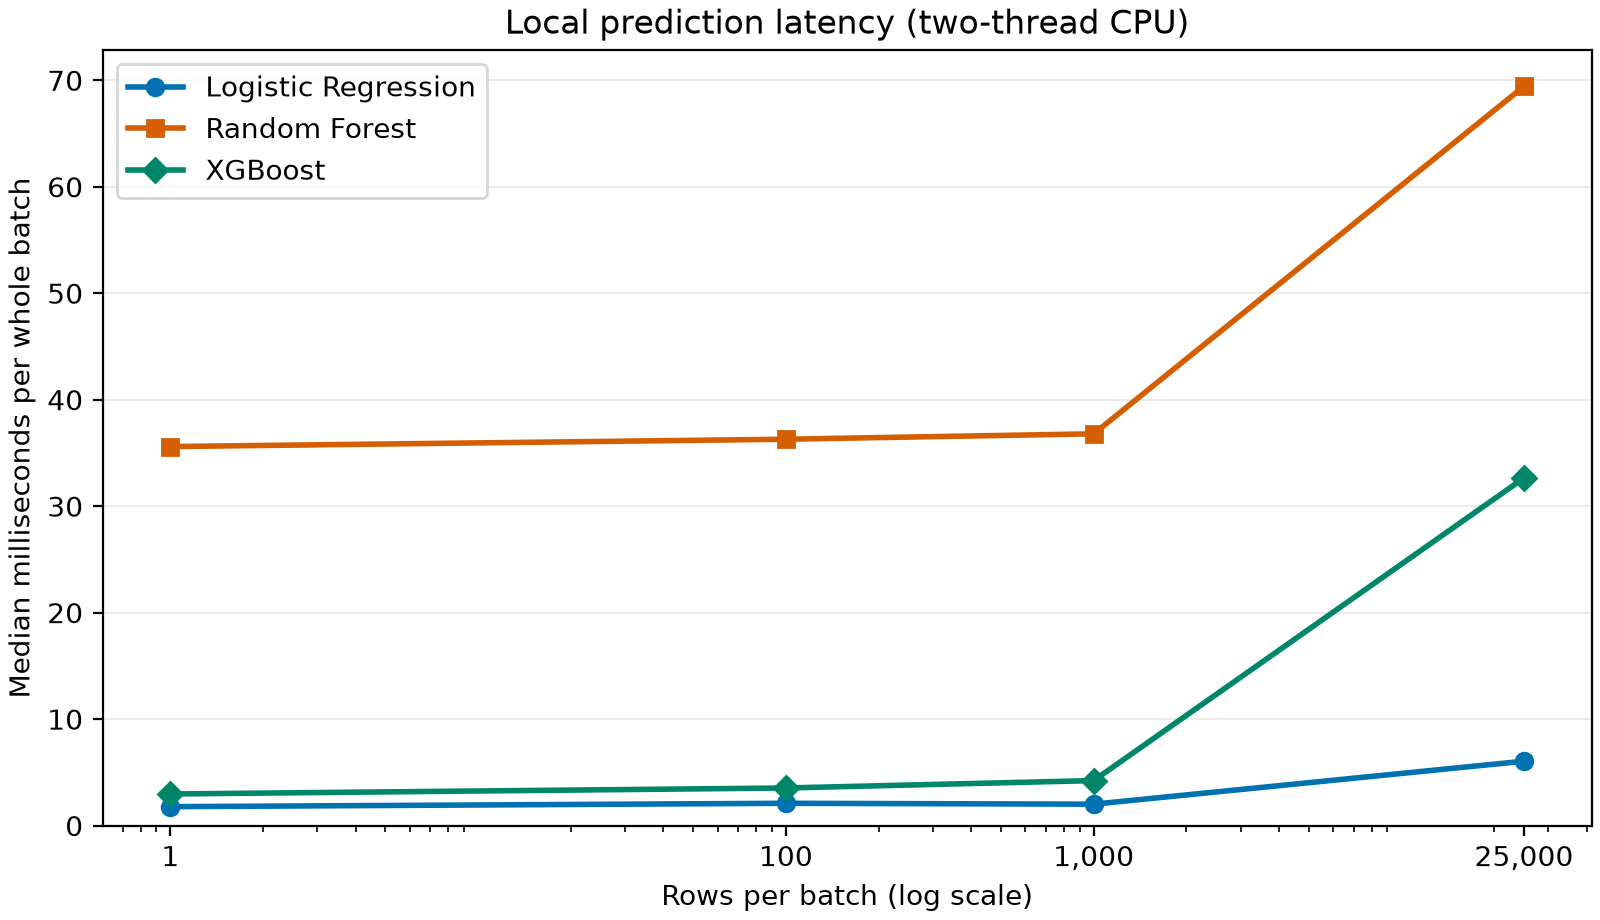

**Interpretation.** Logistic Regression had the lowest recorded median at all four batch sizes. For 25,000 rows, the medians were 6.05 ms for Logistic Regression, 32.65 ms for XGBoost, and 69.43 ms for Random Forest. Each time covers one local probability prediction call for the whole batch.

In [8]:
import json
from pathlib import Path
from xml.etree import ElementTree

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

notebook_path = Path("06_inference_speed.ipynb")
if not notebook_path.is_file():
    notebook_path = Path("notebooks") / notebook_path
saved = json.loads(notebook_path.read_text())
timing_cell = next(cell for cell in saved["cells"] if cell["id"] == "2175781f")
table_html = next(output["data"]["text/html"] for output in timing_cell["outputs"]
                  if "text/html" in output.get("data", {}))
table = ElementTree.fromstring("".join(table_html))
headers = [cell.text for cell in table.findall("./thead/tr/th")]
rows = [[cell.text for cell in row] for row in table.findall("./tbody/tr")]
recorded = pd.DataFrame(rows, columns=headers)
median_column = "Median batch time (ms)"
recorded = recorded.astype({"Batch size": int, median_column: float})
batch_sizes = [1, 100, 1_000, 25_000]
model_names = ["Logistic Regression", "Random Forest", "XGBoost"]
medians = recorded.pivot(index="Batch size", columns="Model", values=median_column)
if list(medians.index) != batch_sizes or set(medians.columns) != set(model_names) or medians.isna().any().any():
    raise ValueError("The saved benchmark does not contain all 12 expected medians.")

fig, ax = plt.subplots(figsize=(8, 4.6), layout="constrained")
for name, color, marker in zip(model_names, ("#0072B2", "#D55E00", "#008669"), ("o", "s", "D"), strict=True):
    ax.plot(batch_sizes, medians[name], color=color, marker=marker, linewidth=2, label=name)
ax.set_xscale("log")
ax.set_xticks(batch_sizes, [f"{size:,}" for size in batch_sizes])
ax.set(xlabel="Rows per batch (log scale)", ylabel="Median milliseconds per whole batch",
       ylim=(0, None), title="Local prediction latency (two-thread CPU)")
ax.grid(axis="y", alpha=0.25)
ax.legend()

figure_dir = notebook_path.resolve().parent.parent / "figures"
figure_dir.mkdir(exist_ok=True)
speed_figure = figure_dir / "inference_speed.png"
fig.savefig(speed_figure, dpi=200)
plt.close(fig)
display(Image(filename=speed_figure, width=800))
largest = medians.loc[25_000]
display(Markdown(
    "**Interpretation.** Logistic Regression had the lowest recorded median at all four batch sizes. "
    f"For 25,000 rows, the medians were {largest['Logistic Regression']:.2f} ms for Logistic Regression, "
    f"{largest['XGBoost']:.2f} ms for XGBoost, and {largest['Random Forest']:.2f} ms for Random Forest. "
    "Each time covers one local probability prediction call for the whole batch."
))